In [27]:
import cupy as cp
import pandas as pd
import seaborn as sns
import cuml
import matplotlib.pyplot as plt
import numpy as np
from xgboost import XGBRegressor
from cuml.ensemble import RandomForestRegressor
from hyperopt import hp, fmin, tpe, Trials, STATUS_OK
from cuml.metrics import r2_score as cuml_r2_score  # GPU Metrics
from cuml.model_selection import train_test_split as cuml_split
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import shap

In [28]:
data = pd.read_csv("/home/aashr/-/Py/Minor_Spec/Papers/1-s2.0-S2666016424001440-mmc1.csv")
data

,ID,Type of MB,Types of contaminants,pH,Compound Mw (g/mol),Compound charge,Compound Kow,min projection (Å),max projection (Å),MB MWCO (Da),MB contact angle (°),MB zeta potential,Total charge,Pressure (kPa),Measurement time (min),Initial concentration of compound (mg/L),compound size (nm),removal rate (%)
0,1,polypropylene (PP),2-(2-Butoxyethoxy)ethanol,7.0,162.229,0.0000,0.711,3.25,8.08,150,50.0,-1.0,0.0000,800.0,10.0,0.16223,0.512,81.5900
1,2,polypropylene (PP),Caprolactam,7.0,113.160,0.0000,0.310,3.92,4.01,150,50.0,-1.0,0.0000,800.0,10.0,0.11316,0.396,82.8500
2,3,polypropylene (PP),Creatine,7.0,131.135,0.0000,-2.864,3.35,4.36,150,50.0,-1.0,0.0000,800.0,10.0,0.13114,0.382,96.6500
3,4,polypropylene (PP),Formaldehyde,7.0,30.026,0.0000,-0.467,2.08,2.34,150,50.0,-1.0,0.0000,800.0,10.0,0.03003,0.221,3.3500
4,5,polypropylene (PP),Isopropanol,7.0,60.096,0.0000,0.255,2.95,3.36,150,50.0,-1.0,0.0000,800.0,10.0,0.06010,0.315,65.2700
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1901,1903,Poly(p-phenylene oxide) (PPO),Indomethacin,7.0,357.790,-1.0000,3.530,5.24,8.54,200,22.6,-1.0,1.0000,500.0,1440.0,0.02000,0.669,97.0719
1902,1904,Poly(p-phenylene oxide) (PPO),Cephalexin hydrate,7.0,347.390,-0.3711,-2.142,4.74,6.38,200,22.6,-1.0,0.3711,500.0,1440.0,0.02000,0.550,95.2613
1903,1905,Poly(p-phenylene oxide) (PPO),Diltiazem,7.0,414.520,0.9374,2.727,6.13,8.50,200,22.6,-1.0,-0.9374,500.0,1440.0,0.02000,0.722,98.3872
1904,1906,Poly(p-phenylene oxide) (PPO),Erythromycin,7.0,733.937,1.0000,2.596,6.83,9.32,200,22.6,-1.0,-1.0000,500.0,1440.0,0.02000,0.798,94.7621


In [29]:
# data = data[[
#     "Compound Mw (g/mol)",
#     "Compound Kow",
#     "Pressure (kPa)",
#     "Measurement time (min)",
#     "Initial concentration of compound (mg/L)",
#     "min projection (Å)",
#     "max projection (Å)",
#     "MB MWCO (Da)",
#     "MB contact angle (°)",
#     "MB zeta potential",
#     "Compound charge",
#     "pH",
#     "removal rate (%)"
# ]].copy()

# data = data.apply(pd.to_numeric, errors="coerce").dropna().reset_index(drop=True)
# data

In [30]:

# df = pd.get_dummies(data, columns=["Type of MB"])
# df = pd.get_dummies(df, columns=[ "Types of contaminants"])
# df = df.drop(columns=["ID"])

df = data.drop(columns=["ID", "Type of MB", "Types of contaminants"]) 
df

,pH,Compound Mw (g/mol),Compound charge,Compound Kow,min projection (Å),max projection (Å),MB MWCO (Da),MB contact angle (°),MB zeta potential,Total charge,Pressure (kPa),Measurement time (min),Initial concentration of compound (mg/L),compound size (nm),removal rate (%)
0,7.0,162.229,0.0000,0.711,3.25,8.08,150,50.0,-1.0,0.0000,800.0,10.0,0.16223,0.512,81.5900
1,7.0,113.160,0.0000,0.310,3.92,4.01,150,50.0,-1.0,0.0000,800.0,10.0,0.11316,0.396,82.8500
2,7.0,131.135,0.0000,-2.864,3.35,4.36,150,50.0,-1.0,0.0000,800.0,10.0,0.13114,0.382,96.6500
3,7.0,30.026,0.0000,-0.467,2.08,2.34,150,50.0,-1.0,0.0000,800.0,10.0,0.03003,0.221,3.3500
4,7.0,60.096,0.0000,0.255,2.95,3.36,150,50.0,-1.0,0.0000,800.0,10.0,0.06010,0.315,65.2700
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1901,7.0,357.790,-1.0000,3.530,5.24,8.54,200,22.6,-1.0,1.0000,500.0,1440.0,0.02000,0.669,97.0719
1902,7.0,347.390,-0.3711,-2.142,4.74,6.38,200,22.6,-1.0,0.3711,500.0,1440.0,0.02000,0.550,95.2613
1903,7.0,414.520,0.9374,2.727,6.13,8.50,200,22.6,-1.0,-0.9374,500.0,1440.0,0.02000,0.722,98.3872
1904,7.0,733.937,1.0000,2.596,6.83,9.32,200,22.6,-1.0,-1.0000,500.0,1440.0,0.02000,0.798,94.7621


In [31]:
# df = df.dropna()

In [32]:
len(df.columns)

15

In [33]:
# Paper-style 6-feature setup: keep the same exact variables used in the study
# and avoid any invalid log transform on negative Kow values.
Y = df["removal rate (%)"].astype(float)
X = df.drop(columns=["removal rate (%)"]).copy()

# Convert all features to numeric and keep only valid rows
X = X.apply(pd.to_numeric, errors="coerce")
Y = Y.loc[X.index]

print(X.head())
print("Shape:", X.shape)

    pH  Compound Mw (g/mol)  Compound charge  Compound Kow  \
0  7.0              162.229              0.0         0.711   
1  7.0              113.160              0.0         0.310   
2  7.0              131.135              0.0        -2.864   
3  7.0               30.026              0.0        -0.467   
4  7.0               60.096              0.0         0.255   

   min projection (Å)  max projection (Å)  MB MWCO (Da)  MB contact angle (°)  \
0                3.25                8.08           150                  50.0   
1                3.92                4.01           150                  50.0   
2                3.35                4.36           150                  50.0   
3                2.08                2.34           150                  50.0   
4                2.95                3.36           150                  50.0   

   MB zeta potential  Total charge  Pressure (kPa)  Measurement time (min)  \
0               -1.0           0.0           800.0            

In [34]:
# Keep the raw Compound Kow values. The paper dataset contains negative Kow values,
# so log10 would produce invalid values and distort the model.
X["Compound Kow"] = pd.to_numeric(X["Compound Kow"], errors="coerce")
# X = X.dropna()
Y = Y.loc[X.index]

print("Negative Kow count:", int((X["Compound Kow"] < 0).sum()))
print("Final X shape:", X.shape)

Negative Kow count: 319
Final X shape: (1906, 14)


In [35]:
X

,pH,Compound Mw (g/mol),Compound charge,Compound Kow,min projection (Å),max projection (Å),MB MWCO (Da),MB contact angle (°),MB zeta potential,Total charge,Pressure (kPa),Measurement time (min),Initial concentration of compound (mg/L),compound size (nm)
0,7.0,162.229,0.0000,0.711,3.25,8.08,150,50.0,-1.0,0.0000,800.0,10.0,0.16223,0.512
1,7.0,113.160,0.0000,0.310,3.92,4.01,150,50.0,-1.0,0.0000,800.0,10.0,0.11316,0.396
2,7.0,131.135,0.0000,-2.864,3.35,4.36,150,50.0,-1.0,0.0000,800.0,10.0,0.13114,0.382
3,7.0,30.026,0.0000,-0.467,2.08,2.34,150,50.0,-1.0,0.0000,800.0,10.0,0.03003,0.221
4,7.0,60.096,0.0000,0.255,2.95,3.36,150,50.0,-1.0,0.0000,800.0,10.0,0.06010,0.315
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1901,7.0,357.790,-1.0000,3.530,5.24,8.54,200,22.6,-1.0,1.0000,500.0,1440.0,0.02000,0.669
1902,7.0,347.390,-0.3711,-2.142,4.74,6.38,200,22.6,-1.0,0.3711,500.0,1440.0,0.02000,0.550
1903,7.0,414.520,0.9374,2.727,6.13,8.50,200,22.6,-1.0,-0.9374,500.0,1440.0,0.02000,0.722
1904,7.0,733.937,1.0000,2.596,6.83,9.32,200,22.6,-1.0,-1.0000,500.0,1440.0,0.02000,0.798


In [36]:
# view = data.drop(columns=["Type of MB", "Types of contaminants"])
print(df.min())
print(df.max())


pH                                            2.20000
Compound Mw (g/mol)                          30.02600
Compound charge                              -2.00000
Compound Kow                                 -6.30000
min projection (Å)                            2.08000
max projection (Å)                            2.34000
MB MWCO (Da)                                 65.00000
MB contact angle (°)                         14.40000
MB zeta potential                            -1.00000
Total charge                                 -1.99610
Pressure (kPa)                              240.00000
Measurement time (min)                       10.00000
Initial concentration of compound (mg/L)      0.00072
compound size (nm)                            0.22100
removal rate (%)                              0.00000
dtype: float64
pH                                            11.0000
Compound Mw (g/mol)                          837.0580
Compound charge                                1.8281
Compound Kow 

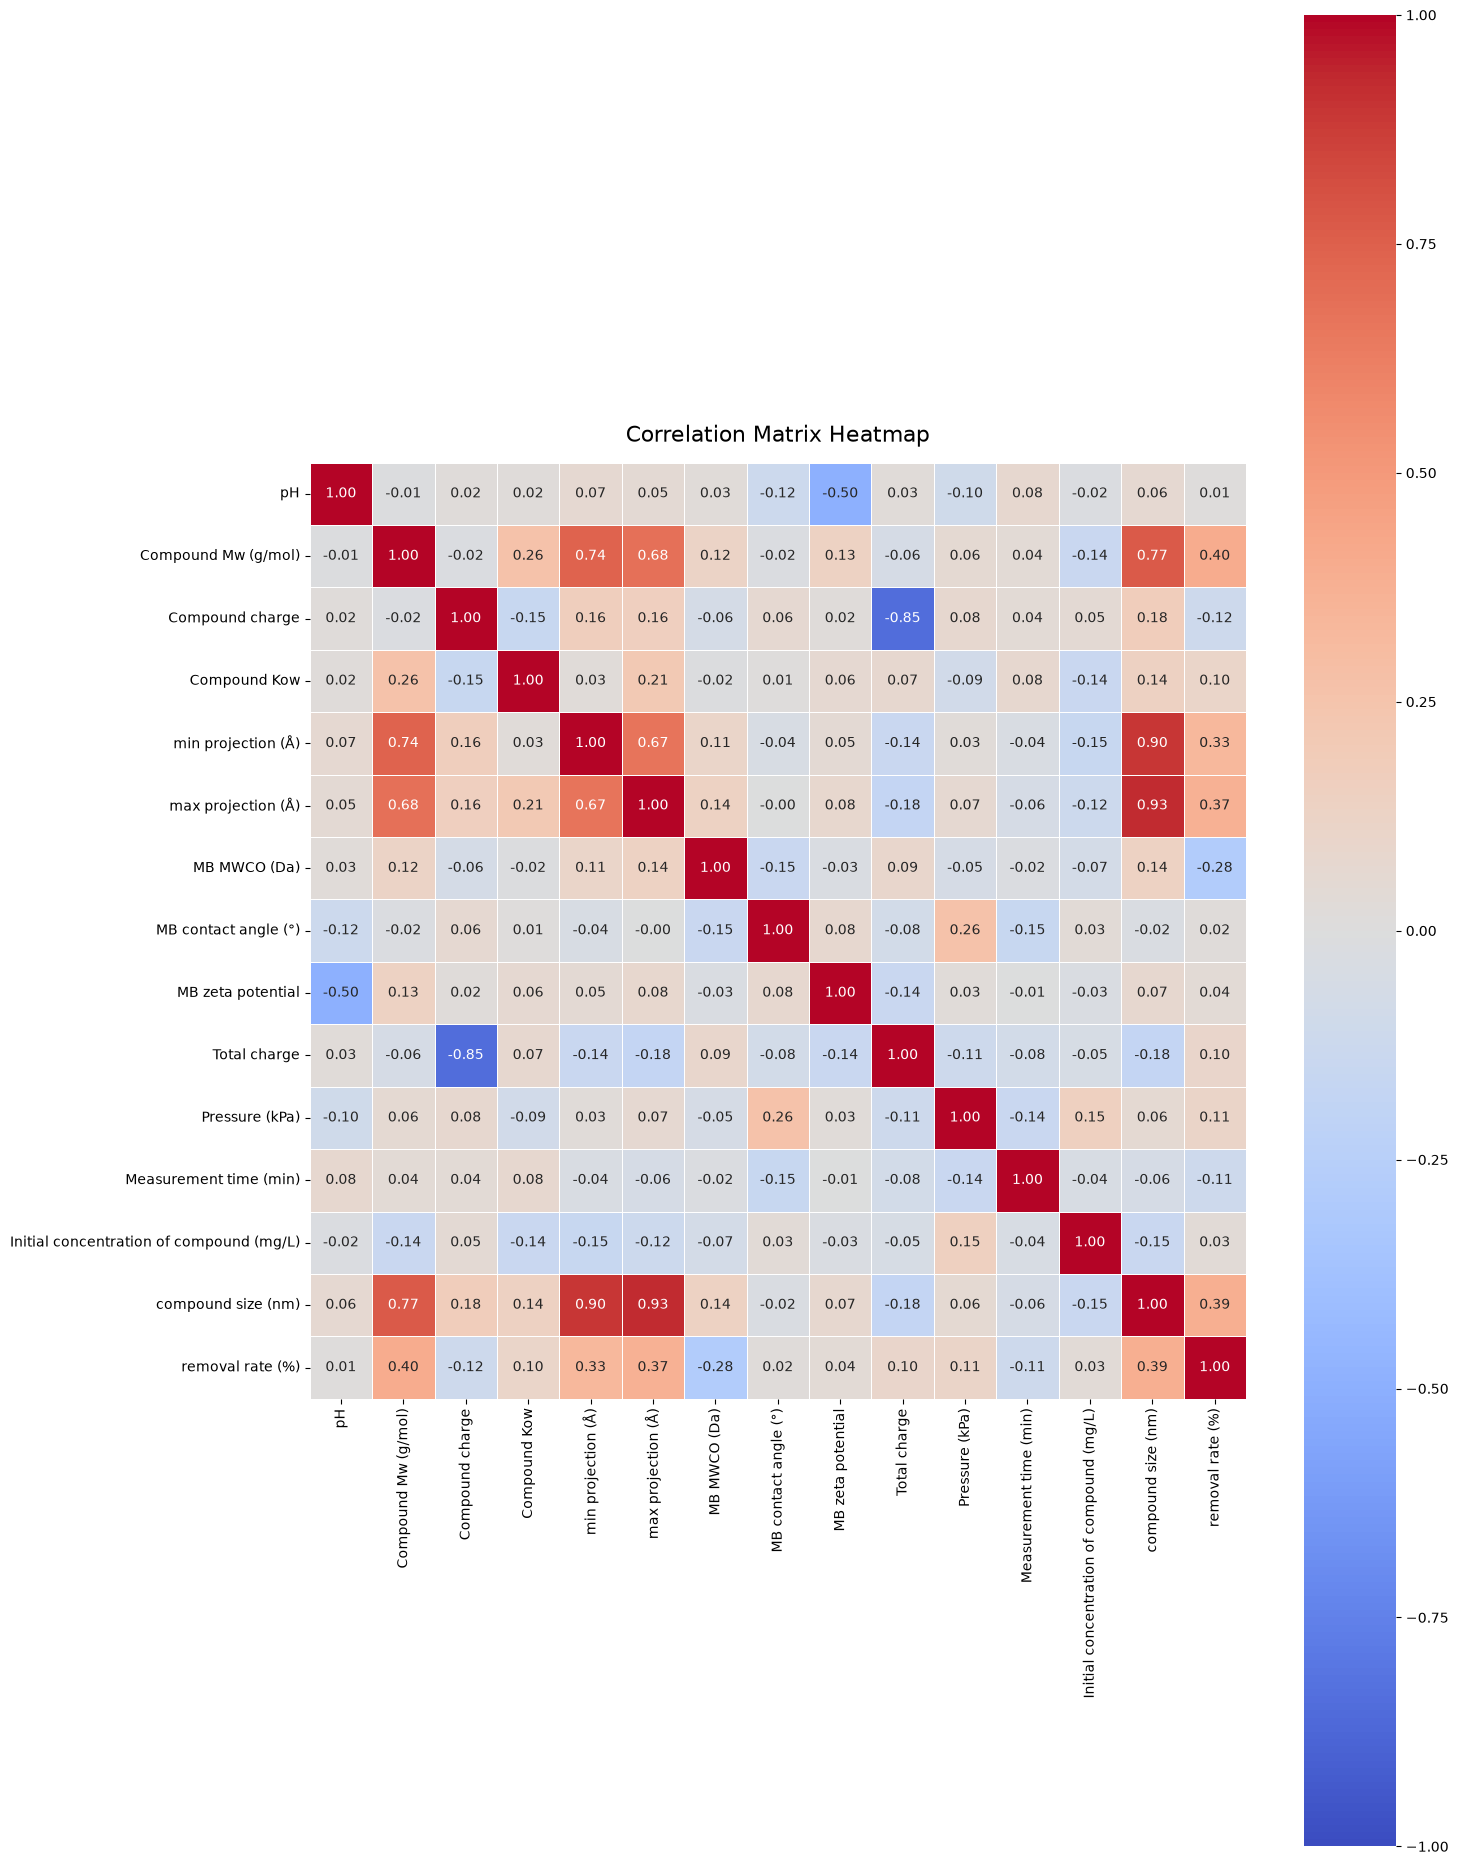

In [37]:
df_num = df.select_dtypes(include=[np.number])
corr = df_num.corr()
# 3. Create a clean heatmap
plt.figure(figsize=(15, 19))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)
plt.title("Correlation Matrix Heatmap", fontsize=16, pad=15)
plt.tight_layout()
plt.show()

In [38]:
# from scipy import stats
# import numpy as np

# z = np.abs(stats.zscore(X))
# mask = (z < 3).all(axis=1)

# X = X[mask]
# Y = Y[mask]
# X

In [39]:
X = X.replace([np.inf, -np.inf], np.nan)
valid_idx = X.dropna().index
X = X.loc[valid_idx]
Y = Y.loc[valid_idx]

In [40]:
print(X.shape)
X

(1906, 14)


,pH,Compound Mw (g/mol),Compound charge,Compound Kow,min projection (Å),max projection (Å),MB MWCO (Da),MB contact angle (°),MB zeta potential,Total charge,Pressure (kPa),Measurement time (min),Initial concentration of compound (mg/L),compound size (nm)
0,7.0,162.229,0.0000,0.711,3.25,8.08,150,50.0,-1.0,0.0000,800.0,10.0,0.16223,0.512
1,7.0,113.160,0.0000,0.310,3.92,4.01,150,50.0,-1.0,0.0000,800.0,10.0,0.11316,0.396
2,7.0,131.135,0.0000,-2.864,3.35,4.36,150,50.0,-1.0,0.0000,800.0,10.0,0.13114,0.382
3,7.0,30.026,0.0000,-0.467,2.08,2.34,150,50.0,-1.0,0.0000,800.0,10.0,0.03003,0.221
4,7.0,60.096,0.0000,0.255,2.95,3.36,150,50.0,-1.0,0.0000,800.0,10.0,0.06010,0.315
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1901,7.0,357.790,-1.0000,3.530,5.24,8.54,200,22.6,-1.0,1.0000,500.0,1440.0,0.02000,0.669
1902,7.0,347.390,-0.3711,-2.142,4.74,6.38,200,22.6,-1.0,0.3711,500.0,1440.0,0.02000,0.550
1903,7.0,414.520,0.9374,2.727,6.13,8.50,200,22.6,-1.0,-0.9374,500.0,1440.0,0.02000,0.722
1904,7.0,733.937,1.0000,2.596,6.83,9.32,200,22.6,-1.0,-1.0000,500.0,1440.0,0.02000,0.798


In [41]:
feature_names = X.columns.tolist()


X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape) 

X_train_gpu = cp.asarray(X_train.values, dtype=cp.float32)
y_train_gpu = cp.asarray(y_train.values, dtype=cp.float32)

Train shape: (1524, 14)
Test shape: (382, 14)


In [42]:
param_space = {
    "n_estimators": hp.quniform("n_estimators",100, 500, 200),
    "max_depth": hp.quniform("max_depth", 3, 7, 2),
    "learning_rate": hp.uniform("learning_rate", 0.01, 0.2),
    "subsample": hp.uniform("subsample", 0.6, 1.0),
    "colsample_bytree": hp.uniform("colsample_bytree", 0.6, 1.0),
    "gamma": hp.uniform("gamma", 0, 0.3),
    "min_child_weight": hp.quniform("min_child_weight", 1, 5, 2)
}

def objective(params):
    params["n_estimators"] = int(params["n_estimators"])
    params["max_depth"] = int(params["max_depth"])
    params["min_child_weight"] = int(params["min_child_weight"])

    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    scores = []

    for train_idx, val_idx in kf.split(X_train):
        train_idx = cp.asarray(train_idx)
        val_idx = cp.asarray(val_idx)
        X_tr, X_val = X_train_gpu[train_idx], X_train_gpu[val_idx]
        y_tr, y_val = y_train_gpu[train_idx], y_train_gpu[val_idx]
    
        model = XGBRegressor(
            objective='reg:squarederror',
            random_state=42,
            device="cuda",       # Forces GPU training
            tree_method="hist",  # Fast GPU histogram build
            **params
        )

        model.fit(X_tr, y_tr)
        pred = model.predict(X_val)
    
        # 5-Fold cross-validation on GPU
        scores.append(cuml_r2_score(y_val, pred))
    
    mean_r2 = float(np.mean(scores))
    return {'loss': -mean_r2, 'status': STATUS_OK}

In [43]:
print("Starting Hyperopt optimization...")
trials = Trials()
best_params = fmin(
    fn=objective,
    space=param_space,
    algo=tpe.suggest,
    max_evals=50,  
    trials=trials
)

print("\n--- Optimization Complete ---")
best_params["n_estimators"] = int(best_params["n_estimators"])
best_params["max_depth"] = int(best_params["max_depth"])
best_params["min_child_weight"] = int(best_params["min_child_weight"])

best_cv_score = -trials.best_trial['result']['loss']
print("Best Parameters:", best_params)
print(f"Best CV R² Score: {best_cv_score:.4f}")

Starting Hyperopt optimization...
100%|██████████| 50/50 [03:16<00:00,  3.92s/trial, best loss: -0.8180075764656067]

--- Optimization Complete ---
Best Parameters: {'colsample_bytree': np.float64(0.7462967533745096), 'gamma': np.float64(0.14351308602219406), 'learning_rate': np.float64(0.17802947381820586), 'max_depth': 6, 'min_child_weight': 4, 'n_estimators': 400, 'subsample': np.float64(0.7977617705129858)}
Best CV R² Score: 0.8180


In [44]:
final_xgb_model = XGBRegressor(
    objective='reg:squarederror',
    random_state=42,
    device="cuda",
    tree_method="hist",
    **best_params
)
final_xgb_model.fit(X_train_gpu, y_train_gpu)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,np.float64(0.7462967533745096)
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",'cuda'
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [45]:
xgb_pred = final_xgb_model.predict(X_test)

xgb_mse = mean_squared_error(y_test, xgb_pred)
xgb_rmse = np.sqrt(xgb_mse)
xgb_mae = mean_absolute_error(y_test, xgb_pred)
xgb_r2 = r2_score(y_test, xgb_pred)

print("\n--- Final Test Set Metrics ---")
print(f"MSE: {xgb_mse:.4f}")
print(f"RMSE: {xgb_rmse:.4f}")
print(f"MAE: {xgb_mae:.4f}")
print(f"R² Score: {xgb_r2:.4f}")


--- Final Test Set Metrics ---
MSE: 128.2187
RMSE: 11.3234
MAE: 7.0892
R² Score: 0.8321


/home/aashr/miniforge3/envs/rapids-26.08/lib/python3.12/site-packages/shap/explainers/_tree.py:265: FutureWarning: In the future, passing feature_perturbation='interventional' without providing a background dataset will raise an error. Please provide a background dataset to continue using the interventional approach or set feature_perturbation='auto' to automatically switch approaches.
  warnings.warn(


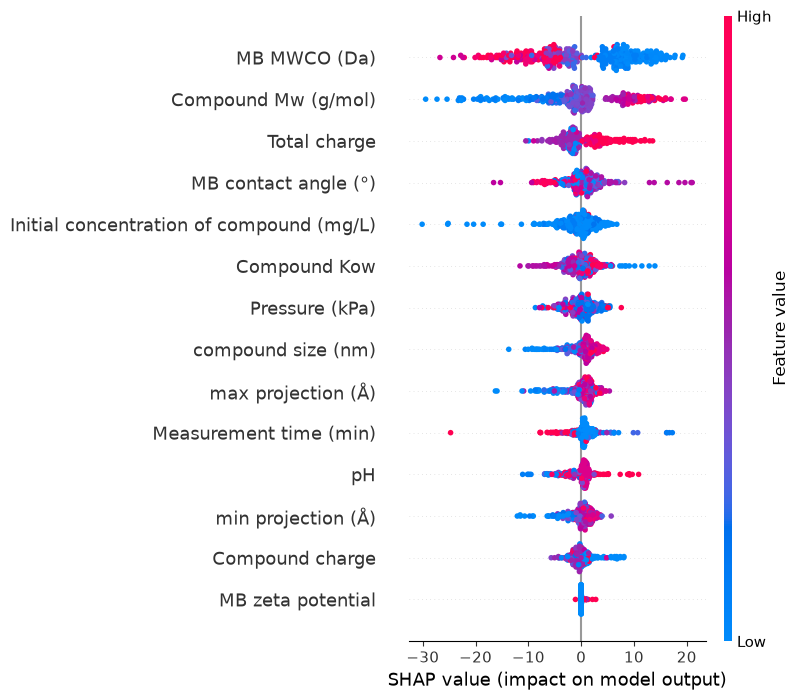

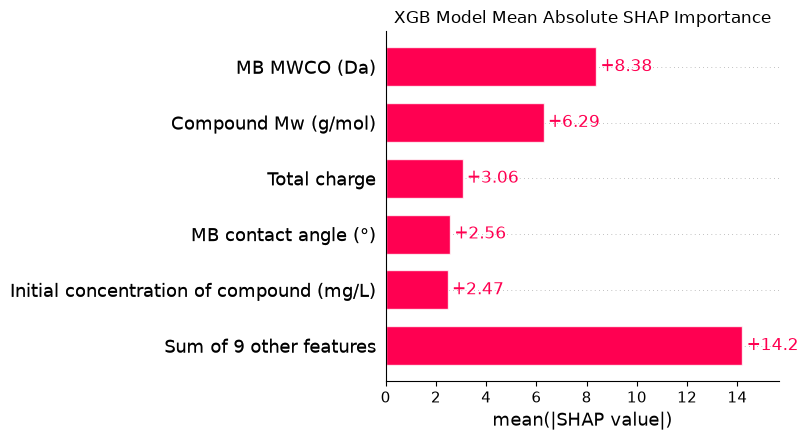


--- Top 6 Most Important Features ---
                                     feature  importance
6                               MB MWCO (Da)    8.380449
1                        Compound Mw (g/mol)    6.293349
9                               Total charge    3.064534
7                       MB contact angle (°)    2.563504
12  Initial concentration of compound (mg/L)    2.472979
3                               Compound Kow    2.163501


In [49]:
explainer = shap.TreeExplainer(final_xgb_model, feature_perturbation="interventional")
shap_test = explainer(X_test)  # Using the new explainer API format

# Summary Plot
shap.summary_plot(shap_test, X_test)

# Bar Plot
shap.plots.bar(shap_test, max_display=6, show=False)
plt.title("XGB Model Mean Absolute SHAP Importance")
plt.tight_layout()
plt.show()

# FIXED: Extract mean absolute values correctly from the SHAP Explanation object
shap_importance = np.abs(shap_test.values).mean(axis=0)

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": shap_importance
}).sort_values(by="importance", ascending=False)

top6 = feature_importance.head(6)
print("\n--- Top 6 Most Important Features ---")
print(top6)

/home/aashr/miniforge3/envs/rapids-26.08/lib/python3.12/site-packages/shap/explainers/_tree.py:265: FutureWarning: In the future, passing feature_perturbation='interventional' without providing a background dataset will raise an error. Please provide a background dataset to continue using the interventional approach or set feature_perturbation='auto' to automatically switch approaches.
  warnings.warn(


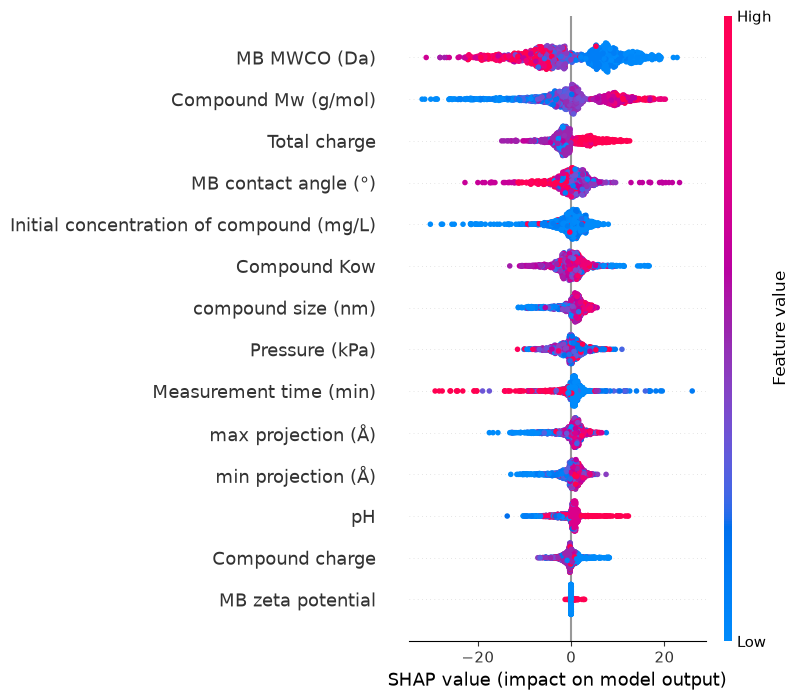

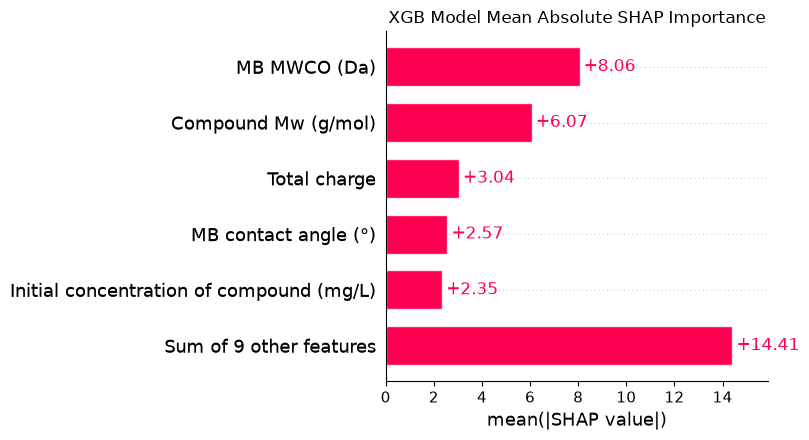

                                     feature  importance
6                               MB MWCO (Da)    8.058425
1                        Compound Mw (g/mol)    6.070029
9                               Total charge    3.042606
7                       MB contact angle (°)    2.566158
12  Initial concentration of compound (mg/L)    2.346580
3                               Compound Kow    2.220920


In [53]:
explainer = shap.TreeExplainer(final_xgb_model, feature_perturbation="interventional")
shap_values = explainer(X_train)  # Using the new explainer API format

# Summary Plot
shap.summary_plot(shap_values, X_train)

# Bar Plot
shap.plots.bar(shap_values, max_display=6, show=False)
plt.title("XGB Model Mean Absolute SHAP Importance")
plt.tight_layout()
plt.show()

# FIXED: Extract mean absolute values correctly from the SHAP Explanation object
shap_importance = np.abs(shap_values.values).mean(axis=0)

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": shap_importance
}).sort_values(by="importance", ascending=False)

top6_features = (
    feature_importance.head(6)
)

print(top6_features)

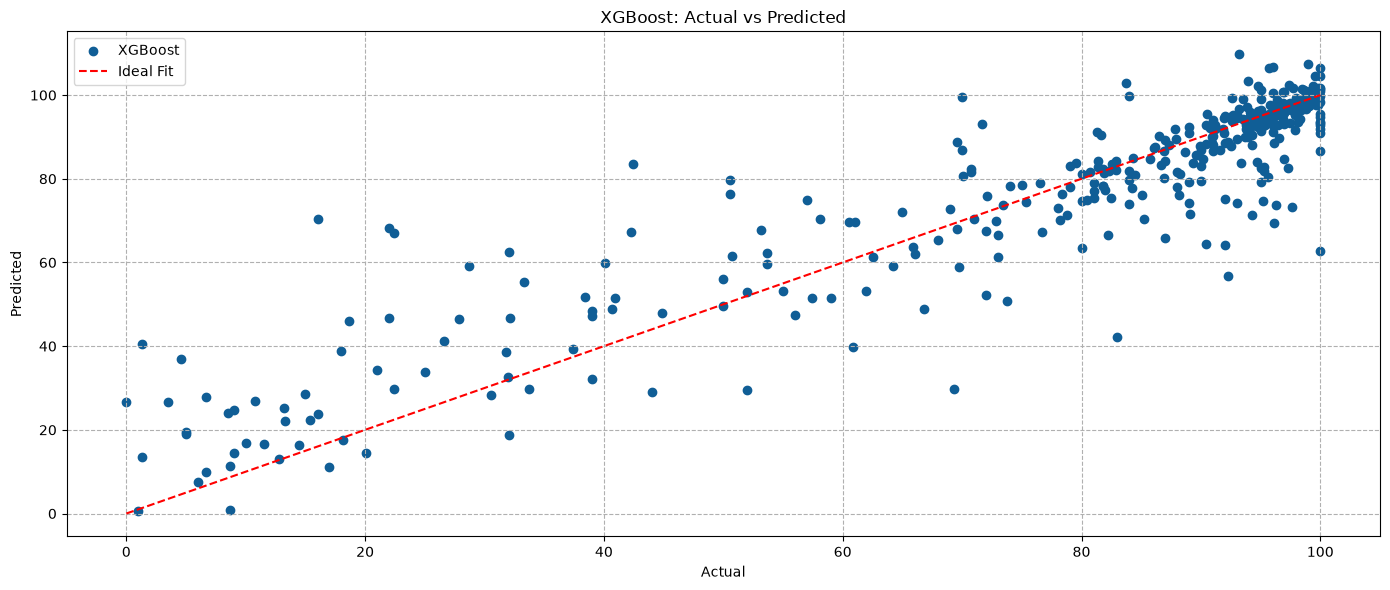

In [48]:


plt.figure(figsize=(14, 6))

plt.scatter(y_test, xgb_pred, color="#105e96", label='XGBoost')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Ideal Fit')
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("XGBoost: Actual vs Predicted")
plt.legend()
plt.grid(True, linestyle='--')


plt.tight_layout()
plt.show()
